# Credit Default: portable inference and exploratory analysis

This notebook demonstrates the integrated backend using the original trained Random Forest. All prediction operations use `PredictionService`, the same service used by FastAPI. It does not fit a model, tune a threshold, save an artifact, or write report files.

**Run all cells in order.** Use a Python 3.12 kernel from the environment installed with `backend/requirements-research.txt`; the model requires scikit-learn **1.6.1**. Start Jupyter from the project root, `backend/`, or `backend/notebooks/`.

The original 204-cell Colab research notebook is preserved separately and is not executed here. The official UCI dataset was restored because the uploaded project omitted its external local CSV. See `backend/data/README.md` for provenance. Sample diagnostics below are not independent held-out performance results.

In [1]:
from pathlib import Path
import sys
import hashlib
import json
import platform

# Resolve the same backend from the root, backend, or notebooks working directory.
working_directory = Path.cwd().resolve()
candidates = []
for parent in (working_directory, *working_directory.parents):
    candidates.extend((parent, parent / "backend"))
backend = next((candidate for candidate in candidates
                if (candidate / "app/services/prediction_service.py").is_file()
                and (candidate / "models/credit_default_model_v1.joblib").is_file()), None)
if backend is None:
    raise RuntimeError("Start this notebook from Integrated_Credit_Default_System, backend, or backend/notebooks.")
if str(backend) not in sys.path:
    sys.path.insert(0, str(backend))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from app.services.prediction_service import PredictionService

model_path = backend / "models/credit_default_model_v1.joblib"
model_hash_before = hashlib.sha256(model_path.read_bytes()).hexdigest()
service = PredictionService(backend)
service.load()
service.require_model()
print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("Model status:", service.health())

Python: 3.12.14
scikit-learn: 1.6.1
Model status: {'status': 'healthy', 'model_loaded': True, 'model_name': 'Credit Default Random Forest', 'model_version': '1.0', 'threshold': 0.5}


## 1. Model identity and the 23 → 38 → 41 contract

The service checks the model checksum, fitted preprocessing schema, target, class ordering, threshold, and metadata when it loads. The 23 customer inputs become 38 engineered columns. The fitted scaler and one-hot encoder transform those into 41 classifier inputs. These counts describe different stages of the same preserved pipeline.

In [2]:
metadata = service.metadata
raw_features = metadata["raw_features"]
summary = {
    "Model": metadata["model_name"],
    "Version": metadata["model_version"],
    "Algorithm": metadata["algorithm"],
    "Target": metadata["target"],
    "Decision threshold": metadata["threshold"],
    "Raw inputs": metadata["raw_feature_count"],
    "Engineered columns": metadata["engineered_feature_count"],
    "Transformed classifier inputs": metadata["processed_feature_count"],
    "Classes": metadata["classes"],
}
print(pd.Series(summary).to_string())
assert (len(raw_features), len(metadata["features"]), len(metadata["processed_features"])) == (23, 38, 41)
assert service.threshold == 0.50
print("\nModel SHA-256:", model_hash_before)

Model                            Credit Default Random Forest
Version                                                   1.0
Algorithm                              RandomForestClassifier
Target                             default.payment.next.month
Decision threshold                                        0.5
Raw inputs                                                 23
Engineered columns                                         38
Transformed classifier inputs                              41
Classes                                                [0, 1]

Model SHA-256: 5f7068b16bf1393578f7fd6e1b37e9c6905a1fca993e20c9775424738006c261


## 2. Bounded exploration of real UCI records

Read the first **500 records** for a small, reproducible demonstration. This is a convenience sample, not a held-out test set or a representative population estimate. The identifier and observed target are retained as data columns but are excluded from model inputs. Monetary values are in the original dataset units; no currency conversion is applied.

In [3]:
dataset_path = backend / "data/processed/UCI_Credit_Card.csv"
sample = pd.read_csv(dataset_path, nrows=500)
target = metadata["target"]
assert set(raw_features + [target, "ID"]).issubset(sample.columns)
assert sample[target].isin([0, 1]).all()
print("Sample shape:", sample.shape)
print("\nFirst five records (selected columns):")
print(sample[["ID", "LIMIT_BAL", "AGE", "PAY_0", target]].head().to_string(index=False))
print("\nObserved outcomes in this 500-record sample:")
print(sample[target].value_counts().sort_index().rename(index={0: "No default", 1: "Default"}).to_string())
print("\nInput data summary:")
print(sample[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]].describe().round(2).to_string())

Sample shape: (500, 25)

First five records (selected columns):
 ID  LIMIT_BAL  AGE  PAY_0  default.payment.next.month
  1      20000   24      2                           1
  2     120000   26     -1                           1
  3      90000   34      0                           0
  4      50000   37      0                           0
  5      50000   57     -1                           0

Observed outcomes in this 500-record sample:
default.payment.next.month
No default    385
Default       115

Input data summary:
       LIMIT_BAL     AGE  BILL_AMT1   PAY_AMT1
count     500.00  500.00     500.00     500.00
mean   170780.00   34.95   56108.22    5613.83
std    130151.72    9.36   80499.28   11725.68
min     10000.00   22.00  -14386.00       0.00
25%     57500.00   28.00    3233.50    1000.00
50%    140000.00   33.00   23199.00    2500.00
75%    240000.00   40.00   70889.25    5706.25
max    630000.00   75.00  507726.00  120093.00


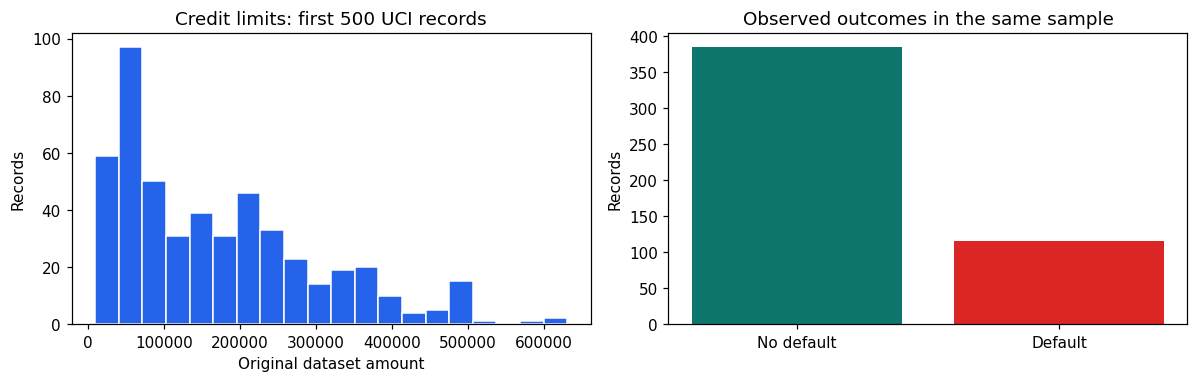

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(sample["LIMIT_BAL"], bins=20, color="#2563eb", edgecolor="white")
axes[0].set(title="Credit limits: first 500 UCI records", xlabel="Original dataset amount", ylabel="Records")
counts = sample[target].value_counts().reindex([0, 1], fill_value=0)
axes[1].bar(["No default", "Default"], counts.to_numpy(), color=["#0f766e", "#dc2626"])
axes[1].set(title="Observed outcomes in the same sample", ylabel="Records")
fig.tight_layout()
plt.show()

## 3. Inspect the original feature preparation

Category normalization and all 15 added features remain in the original backend source. The notebook asks the service to prepare five rows; it does not duplicate the formulas. The original `EDUCATION` mapping is 0/5/6 → 4, and `MARRIAGE` mapping is 0 → 3.

In [5]:
raw_five = sample.loc[:, raw_features].head(5).copy()
engineered_five = service.prepare(raw_five)
transformed_five = service.pipeline.named_steps["preprocessor"].transform(engineered_five)
assert raw_five.shape == (5, 23)
assert engineered_five.shape == (5, 38)
assert transformed_five.shape == (5, 41)
assert engineered_five.columns.tolist() == metadata["features"]
print("Raw → engineered → transformed:", raw_five.shape, "→", engineered_five.shape, "→", transformed_five.shape)
print(engineered_five[["AVG_UTILIZATION", "MAX_DELAY", "DELAY_MONTHS", "AVG_PAY_AMT", "PAY_TO_BILL_RATIO"]].round(4).to_string(index=False))

Raw → engineered → transformed: (5, 23) → (5, 38) → (5, 41)
 AVG_UTILIZATION  MAX_DELAY  DELAY_MONTHS  AVG_PAY_AMT  PAY_TO_BILL_RATIO
          0.0642          2             2     114.8333             0.0894
          0.0237          2             2     833.3333             0.2928
          0.1882          0             0    1836.3333             0.1084
          0.7711          0             0    1398.0000             0.0363
          0.3645          0             0    9841.5000             0.5401


## 4. Single-customer assessment and both original risk conventions

The project originally had two labels for different purposes, and both are preserved:

| Returned field | Original rule |
| --- | --- |
| `prediction` | Default = 1 when probability ≥ 0.50; otherwise 0 |
| `risk_band` | UI band: Low below 0.30; Moderate from 0.30 to below 0.50; High from 0.50 |
| `risk_level` | Original domain score: Low below 0.30; Medium from 0.30 to below 0.60; High from 0.60 |
| `risk_index` | Default probability × 100, rounded to two decimals; higher means greater modeled risk |

A probability between 0.50 and 0.60 consequently has UI band High and domain level Medium. This preserves the original meanings; the model probability and binary decision do not change.

In [6]:
customer = sample.loc[:, raw_features].head(1).to_dict(orient="records")[0]
single = service.predict(customer)
print(pd.Series({key: single[key] for key in [
    "default_probability", "default_probability_percent", "prediction", "prediction_label",
    "risk_band", "risk_level", "risk_index", "threshold", "model_version"
]}).to_string())
print("\nEngineered indicators:")
print(pd.Series(single["indicators"]).to_string())

default_probability                       0.837765
default_probability_percent                  83.78
prediction                                       1
prediction_label               DEFAULT / HIGH RISK
risk_band                                     High
risk_level                                    High
risk_index                                   83.78
threshold                                      0.5
model_version                                  1.0

Engineered indicators:
avg_utilization       0.064200
max_utilization       0.195650
avg_delay            -0.333333
max_delay             2.000000
delayed_months        2.000000
avg_bill           1284.000000
avg_payment         114.833333
pay_to_bill           0.089434
pay_to_limit          0.005742


## 5. Batch assessment of ten records

The central service handles validation, ordering, preserved identifiers, and output fields. The observed target is passed through for inspection; it is not used as an input. This small batch is an inference demonstration.

In [7]:
batch = service.predict_batch(sample.head(10).to_dict(orient="records"))
assert batch["scored_rows"] == 10 and batch["skipped_rows"] == 0
batch_frame = pd.DataFrame(batch["results"])
print(batch_frame[["ID", target, "default_probability", "prediction", "risk_band", "risk_level", "risk_index"]].round(6).to_string(index=False))
np.testing.assert_allclose(batch_frame.loc[0, "default_probability"], single["default_probability"], rtol=0, atol=1e-12)

 ID  default.payment.next.month  default_probability  prediction risk_band risk_level  risk_index
  1                           1             0.837765           1      High       High       83.78
  2                           1             0.578554           1      High     Medium       57.86
  3                           0             0.221010           0       Low        Low       22.10
  4                           0             0.385527           0  Moderate     Medium       38.55
  5                           0             0.209422           0       Low        Low       20.94
  6                           0             0.409606           0  Moderate     Medium       40.96
  7                           0             0.203963           0       Low        Low       20.40
  8                           0             0.318650           0  Moderate     Medium       31.87
  9                           0             0.517651           1      High     Medium       51.77
 10                 

## 6. Original five payment scenarios

Each scenario changes all six payment amounts by the selected factor and asks the same service to regenerate features and infer risk. All other raw inputs remain fixed. Differences describe the model's response to hypothetical inputs; they do not establish a causal effect or guaranteed lending outcome.

      label  factor  default_probability  prediction risk_band risk_level
No payments     0.0             0.835382           1      High       High
       Half     0.5             0.826696           1      High       High
    Current     1.0             0.837765           1      High       High
       +50%     1.5             0.822940           1      High       High
     Double     2.0             0.814388           1      High       High


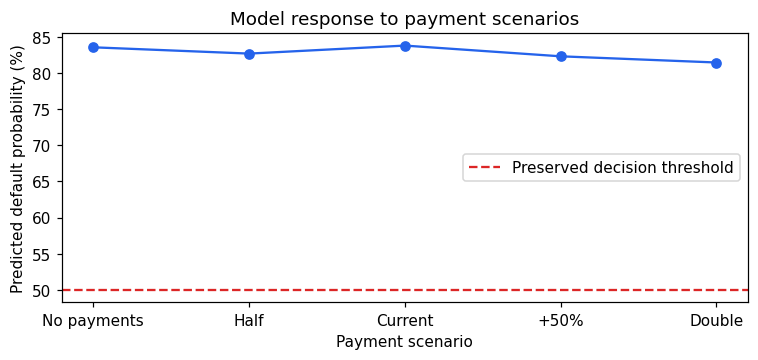

In [8]:
scenarios = service.scenarios(customer, [0.0, 0.5, 1.0, 1.5, 2.0])
scenario_frame = pd.DataFrame(scenarios["scenarios"])
print(scenario_frame[["label", "factor", "default_probability", "prediction", "risk_band", "risk_level"]].round(6).to_string(index=False))
current_probability = scenario_frame.loc[scenario_frame["factor"] == 1.0, "default_probability"].iloc[0]
np.testing.assert_allclose(current_probability, single["default_probability"], rtol=0, atol=1e-12)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(scenario_frame["label"], scenario_frame["default_probability"] * 100, marker="o", color="#2563eb")
ax.axhline(service.threshold * 100, color="#dc2626", linestyle="--", label="Preserved decision threshold")
ax.set(title="Model response to payment scenarios", xlabel="Payment scenario", ylabel="Predicted default probability (%)")
ax.legend()
fig.tight_layout()
plt.show()

## 7. Local explainability for one customer

The backend's original SHAP helper explains the positive class, default = 1. Only one customer and the ten largest absolute contributions are requested. The displayed contributions are a truncated list, so their sum alone is not the complete prediction decomposition.

Method: SHAP TreeExplainer | Positive class: 1
          feature  shap_value  absolute_impact
            PAY_0    0.097336         0.097336
        MAX_DELAY    0.069482         0.069482
     DELAY_MONTHS    0.056266         0.056266
            PAY_2    0.028846         0.028846
      AVG_PAY_AMT    0.023126         0.023126
        AVG_DELAY   -0.018853         0.018853
        LIMIT_BAL    0.016044         0.016044
         PAY_AMT3    0.010490         0.010490
            PAY_3   -0.009500         0.009500
PAY_TO_BILL_RATIO    0.008917         0.008917
Positive SHAP contributions increase the model's default output. These are model associations, not causal effects.


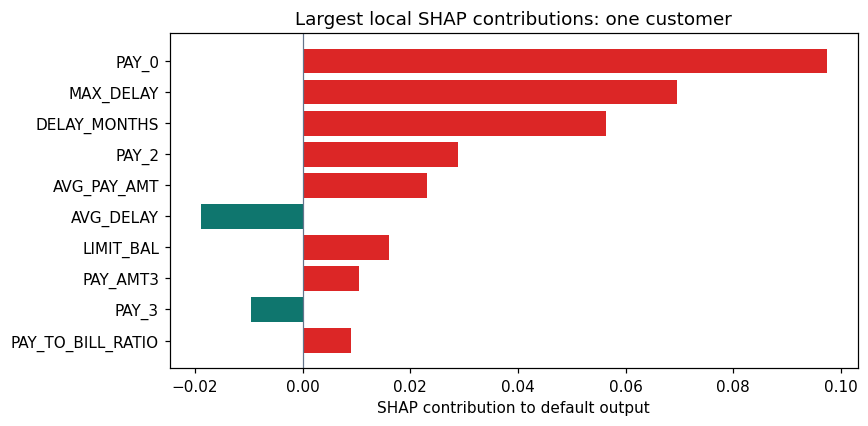

In [9]:
explanation = service.explain(customer, top_n=10)
explanation_frame = pd.DataFrame(explanation["features"])
assert len(explanation_frame) == 10
assert np.isfinite(explanation_frame["shap_value"]).all()
print("Method:", explanation["method"], "| Positive class:", explanation["positive_class"])
print(explanation_frame.round(6).to_string(index=False))
print(explanation["note"])
fig, ax = plt.subplots(figsize=(8, 4))
plot_rows = explanation_frame.iloc[::-1]
ax.barh(plot_rows["feature"], plot_rows["shap_value"], color=np.where(plot_rows["shap_value"] >= 0, "#dc2626", "#0f766e"))
ax.axvline(0, color="#64748b", linewidth=0.8)
ax.set(title="Largest local SHAP contributions: one customer", xlabel="SHAP contribution to default output")
fig.tight_layout()
plt.show()

## 8. Fitted feature importance

These are the saved forest's actual impurity-based importance values. They are distinct from the local SHAP explanation and are not fabricated global SHAP scores. The service exposes both 41 transformed features and 38 grouped model-input features, aggregating one-hot columns back to their source category.

Method: Random Forest mean decrease in impurity (fitted model)
          feature  importance
            PAY_0    0.119227
        MAX_DELAY    0.100665
     DELAY_MONTHS    0.097164
        AVG_DELAY    0.080596
            PAY_2    0.043161
            PAY_3    0.034650
      AVG_PAY_AMT    0.029642
     AVG_BILL_AMT    0.023691
PAY_TO_BILL_RATIO    0.023186
        LIMIT_BAL    0.022125
  MAX_UTILIZATION    0.022059
    UTILIZATION_1    0.021519


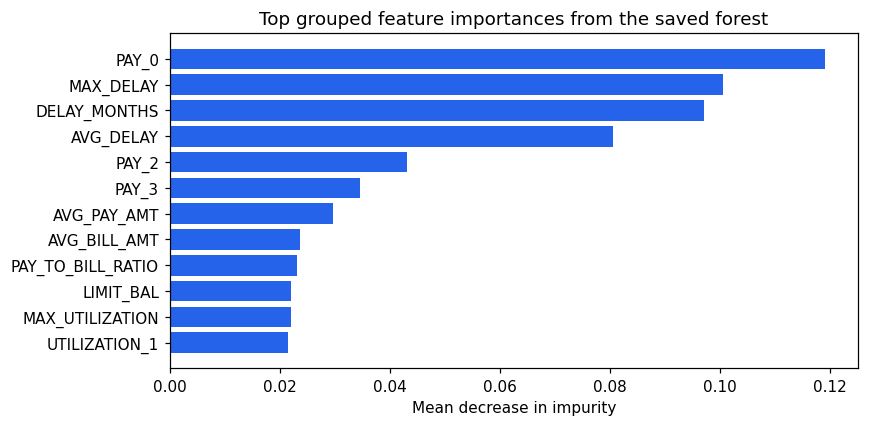

In [10]:
importance = service.feature_importance()
assert len(importance["features"]) == 41
assert len(importance["aggregated_features"]) == 38
importance_frame = pd.DataFrame(importance["aggregated_features"])
print("Method:", importance["method"])
print(importance_frame.head(12).round(6).to_string(index=False))
assert np.isclose(importance_frame["importance"].sum(), 1.0)
fig, ax = plt.subplots(figsize=(8, 4))
plot_rows = importance_frame.head(12).iloc[::-1]
ax.barh(plot_rows["feature"], plot_rows["importance"], color="#2563eb")
ax.set(title="Top grouped feature importances from the saved forest", xlabel="Mean decrease in impurity")
fig.tight_layout()
plt.show()

## 9. Historical supplied metrics, clearly labeled

The following values come from the original uploaded regulatory report. They are retained unchanged and were **not independently re-evaluated by this notebook**. The convenience sample above is not used to claim a new test accuracy, ROC curve, or confusion matrix.

In [11]:
historical = service.metrics
assert historical["verified_in_this_integration"] is False
print("Source:", historical["source"])
print("Independently verified in this integration:", historical["verified_in_this_integration"])
print(pd.Series(historical["metrics"], name="Historical reported value").to_string())

Source: Original uploaded reports/credit_risk_regulatory_report.json (historical results)
Independently verified in this integration: False
accuracy     0.7768
precision    0.4962
recall       0.5863
f1           0.5375
roc_auc      0.7777
pr_auc       0.5548


## 10. Verify the read-only model invariant

The notebook calls no fitting or serialization operation, and its cells write no report/data files. Saving this notebook merely stores the code and displayed outputs. The shipped model checksum must still match its initial value.

In [12]:
model_hash_after = hashlib.sha256(model_path.read_bytes()).hexdigest()
assert model_hash_after == model_hash_before == metadata["model_sha256"]
print("Model SHA-256 unchanged:", model_hash_after)
print("Checks complete: 23 raw inputs → 38 engineered columns → 41 transformed inputs.")
print("Single prediction, 10-row batch, five scenarios, one-customer SHAP, fitted importance, and historical metrics completed.")
print("No model training, threshold change, artifact serialization, or report-file write was performed.")

Model SHA-256 unchanged: 5f7068b16bf1393578f7fd6e1b37e9c6905a1fca993e20c9775424738006c261
Checks complete: 23 raw inputs → 38 engineered columns → 41 transformed inputs.
Single prediction, 10-row batch, five scenarios, one-customer SHAP, fitted importance, and historical metrics completed.
No model training, threshold change, artifact serialization, or report-file write was performed.
